# Proyecto Integrador de Métodos Numéricos

## Informe final: implementación, análisis y consolidación

**Integrantes:** Jorge Zainea Maya, Juan Pablo Navarrete y Valeria Villamil Sandoval  
**Curso:** Métodos Numéricos — Pregrado en Ciencia de Datos  
**Profesor:** Edwin Muñoz  
**Fecha:** noviembre de 2026


## 1. Declaración de uso de inteligencia artificial

**Codex (OpenAI)** se empleó para implementar y revisar el código experimental. **Claude (Anthropic)** se empleó para diseñar instrucciones de trabajo del código y estructura del informe.

## 2. Configuración, entorno y parámetros

La celda siguiente usa las versiones que ya ofrece el entorno (sin instalar ni fijar Python o paquetes). `N_BASE=100` se usa para sensibilidad a `p0`; `N_FIGURAS=400` conserva la resolución de los mapas del informe. El modo rápido reduce las mallas de exploración, la cantidad de pasos probados y las repeticiones del microbenchmark, pero mantiene la tolerancia y el tope configurados.

`ALPHA` controla DN y `DELTA_TAU` controla W4 de forma independiente. Esta implementación de W4 utiliza `c=2` y `0<Δτ<1`.

La malla es determinista. No se usa generador pseudoaleatorio ni semilla activa. Los tiempos dependen de la máquina y pequeñas diferencias de punto flotante entre plataformas pueden mover unos pocos nodos cercanos a fronteras caóticas.

In [1]:
from __future__ import annotations

import os
import sys
import time
from dataclasses import dataclass
from importlib.metadata import version as version_paquete
from math import acos, cos, pi, sqrt
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from numpy.typing import NDArray

In [2]:
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("SciPy instalado:", version_paquete("scipy"), "(se importa funcionalmente solo en Validación)")
print("Matplotlib:", version_paquete("matplotlib"))
print("pandas:", pd.__version__)
assert sys.version_info >= (3, 10), "Se requiere Python 3.10 o posterior y las bibliotecas indicadas."

# Para nbconvert se puede seleccionar el modo rápido con la variable de entorno
# MODO_RAPIDO=1. En Colab basta editar esta asignación antes de Ejecutar todo.
MODO_RAPIDO = os.environ.get("MODO_RAPIDO", "0") == "1"
MODO_COMPLETO = not MODO_RAPIDO
assert MODO_RAPIDO != MODO_COMPLETO

DOMINIO = (-5.0, 5.0)
TOLERANCIA = 1e-6
MAX_ITER = 1000
DELTA_TAU = 0.5
ALPHA = 0.5
C_FRICTION = 2.0
N_BASE = 100
N_FIGURAS = 400
P0_BASE = (0.0, 0.0)  # Supuesto del equipo para el caso multidimensional.
LIMITE_DIVERGENCIA = 1e6
TOL_SINGULAR_REL = 1e-12
TOL_ESTABILIZACION_PP = 0.5
TOPE_SENSIBILIDAD = (10, 20, 50, 100, 200, 500, 1000)

if MODO_RAPIDO:
    MALLA_REFINAMIENTO = (20, 40)
    N_MAPA = 40
    N_VALIDACION = 40
    N_BARRIDO = 40
    TAUS = (0.25, 0.50, 0.75)
    P0_CASOS = ((0.0, 0.0), (0.05, 0.0), (0.0, 0.05))
    LADO_MICRO = 10
    ITER_MICRO = 30
    REP_MICRO = 3
    CALENTAMIENTOS_MICRO = 1
else:
    MALLA_REFINAMIENTO = (40, 100, 200, 400)
    N_MAPA = N_FIGURAS
    N_VALIDACION = N_BASE
    N_BARRIDO = 200
    TAUS = (0.10, 0.25, 0.50, 0.75, 0.90)
    P0_CASOS = ((0.0, 0.0), (0.05, 0.0), (-0.05, 0.0), (0.0, 0.05), (0.0, -0.05))
    LADO_MICRO = 50
    ITER_MICRO = 250
    REP_MICRO = 30
    CALENTAMIENTOS_MICRO = 3

RESULTS_DIR = Path("results") / "colab"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
INICIO_CUADERNO = time.perf_counter()

def paso_metodo(metodo):
    """Paso de referencia: NR completo, DN con ALPHA y W4 con DELTA_TAU."""
    return {"NR": 1.0, "DN": ALPHA, "W4": DELTA_TAU}[metodo.upper()]


def make_mesh(n):
    assert n % 2 == 0, "La resolución debe ser par para omitir el origen exacto."
    valores = np.linspace(DOMINIO[0], DOMINIO[1], n, dtype=np.float64)
    return np.meshgrid(valores, valores, indexing="xy")

print("Modo:", "RÁPIDO" if MODO_RAPIDO else "COMPLETO")
print("Refinamiento:", MALLA_REFINAMIENTO, "| N mapa:", N_MAPA,
      "| N barrido paso:", N_BARRIDO)
print("Tope:", MAX_ITER, "| tolerancia:", TOLERANCIA,
      "| alpha DN:", ALPHA, "| paso W4:", DELTA_TAU, "| c:", C_FRICTION)
print("Carpeta de salida: results/colab (ruta relativa al cuaderno)")

Python: 3.13.17
NumPy: 2.5.4
SciPy instalado: 1.18.1 (se importa funcionalmente solo en Validación)
Matplotlib: 3.11.2
pandas: 3.1.1
Modo: COMPLETO
Refinamiento: (40, 100, 200, 400) | N mapa: 400 | N barrido paso: 200
Tope: 1000 | tolerancia: 1e-06 | alpha DN: 0.5 | paso W4: 0.5 | c: 2.0
Carpeta de salida: results/colab (ruta relativa al cuaderno)


## 3. El sistema, Jacobiano y raíces analíticas

La implementación del sistema está integrada en esta celda; no requiere un archivo `system.py` externo. El sistema tiene cuatro raíces y la sustitución `u=x²` produce la cúbica `u³−4u²+1=0`. Se verifican las raíces sustituyéndolas en ambas ecuaciones.

In [3]:
"""The two-equation system and its analytic reference roots."""

def evaluate(x: np.ndarray, y: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Evaluate F1=x^2+y^2-4 and F2=x^2*y-1 elementwise."""
    return x * x + y * y - 4.0, x * x * y - 1.0


def jacobian_entries(
    x: np.ndarray, y: np.ndarray
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """Return the four entries of the Jacobian, elementwise."""
    return 2.0 * x, 2.0 * y, 2.0 * x * y, x * x


def analytic_roots() -> np.ndarray:
    """Return the four roots from the reduced cubic in x^2.

    Substitution y=1/x^2 reduces the system to u^3-4u^2+1=0,
    where u=x^2.  The two positive cubic roots are evaluated by the
    trigonometric formula; x has both signs and y=1/u.
    """
    theta = acos(101.0 / 128.0) / 3.0
    u_large = 4.0 / 3.0 + (8.0 / 3.0) * cos(theta)
    u_small = 4.0 / 3.0 + (8.0 / 3.0) * cos(theta - 2.0 * pi / 3.0)
    x_large, x_small = sqrt(u_large), sqrt(u_small)
    y_large, y_small = 1.0 / u_large, 1.0 / u_small
    return np.array(
        [
            [x_large, y_large],
            [-x_large, y_large],
            [x_small, y_small],
            [-x_small, y_small],
        ],
        dtype=np.float64,
    )

RAICES = analytic_roots()
F1_RAICES, F2_RAICES = evaluate(RAICES[:, 0], RAICES[:, 1])
TABLA_RAICES = pd.DataFrame({
    "raíz": ["R1", "R2", "R3", "R4"],
    "x*": RAICES[:, 0], "y*": RAICES[:, 1],
    "||F(x*)||₂": np.hypot(F1_RAICES, F2_RAICES),
})
display(TABLA_RAICES)

,raíz,x*,y*,||F(x*)||₂
0,R1,1.983792,0.254102,4.577567e-16
1,R2,-1.983792,0.254102,4.577567e-16
2,R3,0.733077,1.860806,3.552714e-15
3,R4,-0.733077,1.860806,3.552714e-15


## 4. Factorización `J=UDL` y acciones `X`, `Y`

Para el Jacobiano `J=[[2x,2y],[2xy,x²]]`, con `δ=x²−2y²`, se usan `U=[[1,2y/x²],[0,1]]`, `D=diag(2δ/x,x²)` y `L=[[1,0],[2y/x,1]]`. Aquí `U` y `L` son triangulares unitarias y `D` es diagonal. W4 aplica `X=L⁻¹` y `Y=D⁻¹U⁻¹`, por lo que `XY=J⁻¹` siempre que `xδ≠0`. Las expresiones explícitas evitan formar la inversa completa; no eliminan el costo `O(n³)` de una factorización densa general (ni su costo equivalente en Newton). Aplicar factores a un vector cuesta `O(n²)`. El constructor matricial `factor_matrices` sirve para inspección; las actualizaciones aplican directamente las fórmulas de `apply_x` y `apply_y`. En este problema de dimensión fija 2, son vectorizadas y se comparan por el tiempo medido por punto-iteración.

In [4]:
"""UDL operations for the Jacobian of the selected 2D system.

For ``J = U D L``, the factors are unit triangular matrices U and L and a
diagonal D. W4 uses ``Y = D^{-1} U^{-1}`` and ``X = L^{-1}``. No generic
factorization or high-level system solver is called.
"""

FloatArray = NDArray[np.float64]
BoolArray = NDArray[np.bool_]


def factor_matrices(
    x: FloatArray, y: FloatArray
) -> tuple[FloatArray, FloatArray, FloatArray, FloatArray, FloatArray]:
    """Build U, D, L, X=L⁻¹, and Y=D⁻¹U⁻¹ for regular points.

    The leading dimensions index points; the last two dimensions are the
    matrix rows and columns. This is intended for verification and inspection;
    the iterative solver uses the cheaper vector formulas below.
    """
    x, y = np.broadcast_arrays(
        np.asarray(x, dtype=np.float64), np.asarray(y, dtype=np.float64)
    )
    diagonal = x * x - 2.0 * y * y
    if np.any(x == 0.0) or np.any(diagonal == 0.0):
        raise ValueError("UDL factors require x != 0 and x² - 2y² != 0")

    u = np.zeros(x.shape + (2, 2), dtype=np.float64)
    d = np.zeros_like(u)
    l = np.zeros_like(u)
    factor_x = np.zeros_like(u)
    factor_y = np.zeros_like(u)

    u[..., 0, 0], u[..., 0, 1], u[..., 1, 1] = 1.0, 2.0 * y / x**2, 1.0
    d[..., 0, 0], d[..., 1, 1] = 2.0 * diagonal / x, x**2
    l[..., 0, 0], l[..., 1, 0], l[..., 1, 1] = 1.0, 2.0 * y / x, 1.0
    factor_x[..., 0, 0], factor_x[..., 1, 0], factor_x[..., 1, 1] = (
        1.0,
        -2.0 * y / x,
        1.0,
    )
    factor_y[..., 0, 0] = x / (2.0 * diagonal)
    factor_y[..., 0, 1] = -y / (x * diagonal)
    factor_y[..., 1, 1] = 1.0 / x**2
    return u, d, l, factor_x, factor_y


def jacobian_scale_and_determinant(
    x: FloatArray, y: FloatArray
) -> tuple[FloatArray, FloatArray]:
    """Return an infinity-row-sum scale and determinant of J elementwise."""
    j11, j12 = 2.0 * x, 2.0 * y
    j21, j22 = 2.0 * x * y, x * x
    scale = np.maximum(np.abs(j11) + np.abs(j12), np.abs(j21) + np.abs(j22))
    determinant = j11 * j22 - j12 * j21
    return scale, determinant


def singular_jacobian_mask(
    x: FloatArray, y: FloatArray, relative_tolerance: float
) -> BoolArray:
    """Detect singular or numerically near-singular Jacobians elementwise."""
    scale, determinant = jacobian_scale_and_determinant(x, y)
    return (scale == 0.0) | (
        np.abs(determinant) <= relative_tolerance * scale * scale
    )


def pivot_failure_mask(
    x: FloatArray, y: FloatArray, relative_tolerance: float
) -> BoolArray:
    """Detect zero or relatively tiny diagonal pivots in the UDL factors."""
    scale, _ = jacobian_scale_and_determinant(x, y)
    diagonal = x * x - 2.0 * y * y
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        d11 = np.divide(
            2.0 * diagonal,
            x,
            out=np.full_like(x, np.inf, dtype=np.float64),
            where=x != 0.0,
        )
        d22 = x * x
        failed = singular_jacobian_mask(x, y, relative_tolerance)
        failed |= (x == 0.0) | (scale == 0.0)
        failed |= np.abs(d11) <= relative_tolerance * scale
        failed |= np.abs(d22) <= relative_tolerance * scale
    return failed


def apply_y(
    x: FloatArray,
    y: FloatArray,
    rhs1: FloatArray,
    rhs2: FloatArray,
) -> tuple[FloatArray, FloatArray]:
    """Compute ``D^{-1} U^{-1} rhs`` for safe (nonzero-pivot) points."""
    diagonal = x * x - 2.0 * y * y
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        first = x / (2.0 * diagonal) * rhs1 - y / (x * diagonal) * rhs2
        second = rhs2 / (x * x)
    return first, second


def apply_x(
    x: FloatArray, y: FloatArray, vector1: FloatArray, vector2: FloatArray
) -> tuple[FloatArray, FloatArray]:
    """Compute ``L^{-1} vector`` for safe (nonzero-pivot) points."""
    return vector1, vector2 - (2.0 * y / x) * vector1

## 5. Métodos y clasificación de las mallas

Las celdas incluyen las actualizaciones de NR, DN y W4, los estados terminales y el recorrido vectorizado de la malla; no requieren módulos externos del proyecto. El criterio de parada es `||F(x_n)||₂ < 10⁻⁶`: el residuo mide el cumplimiento de las ecuaciones, no la distancia a la raíz. Para cada nodo se conserva la raíz R1–R4 o una clase terminal: divergencia, agotamiento, Jacobiano singular o pivote UDL. Las tasas de éxito y asignación a cada raíz se calculan sobre todos los `N²` puntos iniciales; las proporciones R1–R4 suman la tasa de éxito. El W4 puede registrar además su distancia mínima recorrida a las curvas singulares.

### 5.1 Newton–Raphson


In [5]:
"""Newton--Raphson update specialized to the project's 2D system."""



FloatArray = NDArray[np.float64]


def correction(
    x: FloatArray, y: FloatArray, f1: FloatArray, f2: FloatArray
) -> tuple[FloatArray, FloatArray]:
    """Return the explicit solution of ``J(x,y) delta = F(x,y)``.

    The formula is the closed 2x2 inverse action; it does not call a
    high-level linear solver. The basin runner checks singularity first.
    """
    denominator = x * x - 2.0 * y * y
    delta_x = x / (2.0 * denominator) * f1 - y / (x * denominator) * f2
    delta_y = -y / denominator * f1 + f2 / denominator
    return delta_x, delta_y


def update(
    x: FloatArray, y: FloatArray, f1: FloatArray, f2: FloatArray
) -> tuple[FloatArray, FloatArray]:
    """Perform one full Newton step ``(x,y) - J^{-1}F``."""
    delta_x, delta_y = correction(x, y, f1, f2)
    return x - delta_x, y - delta_y

nr_update = update

### 5.2 Newton amortiguado


In [6]:
"""Damped Newton update specialized to the project's 2D system."""



FloatArray = NDArray[float]


def update(
    x: FloatArray,
    y: FloatArray,
    f1: FloatArray,
    f2: FloatArray,
    alpha: float,
) -> tuple[FloatArray, FloatArray]:
    """Apply the fixed damping factor to the Newton correction each step."""
    if not 0.0 < alpha <= 1.0:
        raise ValueError("alpha must satisfy 0 < alpha <= 1")
    delta_x, delta_y = correction(x, y, f1, f2)
    return x - alpha * delta_x, y - alpha * delta_y

dn_update = update

### 5.3 W4


In [7]:
"""One explicit W4 update for the project's 2D nonlinear system."""

FloatArray = NDArray[float]


def update(
    x: FloatArray,
    y: FloatArray,
    p: FloatArray,
    q: FloatArray,
    f1: FloatArray,
    f2: FloatArray,
    step: float,
    friction: float,
) -> tuple[FloatArray, FloatArray, FloatArray, FloatArray]:
    """Advance position and artificial momentum by one W4 iteration."""
    if not 0.0 < step < 1.0:
        raise ValueError("W4 requires 0 < step < 1 in the studied formulation")
    if friction != 2.0:
        raise ValueError("This W4 implementation uses the studied friction c = 2")
    y1, y2 = apply_y(x, y, f1, f2)
    xp, yp = apply_x(x, y, p, q)
    p_next = (1.0 - friction * step) * p - step * y1
    q_next = (1.0 - friction * step) * q - step * y2
    return x + step * xp, y + step * yp, p_next, q_next

w4_update = update

### 5.4 Estados terminales


In [8]:
"""Shared outcomes returned by the vectorized basin runner."""

from __future__ import annotations

from dataclasses import dataclass
from enum import IntEnum

import numpy as np


class Status(IntEnum):
    """Terminal state assigned to an initial point."""

    ACTIVE = 0
    CONVERGED = 1
    DIVERGED = 2
    MAX_ITERATIONS = 3
    SINGULAR_JACOBIAN = 4
    UDL_PIVOT_FAILURE = 5


STATUS_NAMES = {status.value: status.name.lower() for status in Status}


@dataclass(frozen=True)
class BasinResult:
    """Per-point classifications, residuals, and batch iteration count."""

    roots: np.ndarray
    statuses: np.ndarray
    iterations: np.ndarray
    residuals: np.ndarray
    batch_iterations: int
    minimum_distance_x0: np.ndarray | None = None
    minimum_distance_diagonal: np.ndarray | None = None
    minimum_distance_singular_union: np.ndarray | None = None

### 5.5 Resolución de cuencas


In [9]:
"""Vectorized, hand-coded basin solvers for the selected 2D system."""

from __future__ import annotations

import numpy as np



def _nearest_root_indices(x: np.ndarray, y: np.ndarray) -> np.ndarray:
    roots = analytic_roots()
    distances = (x[:, None] - roots[None, :, 0]) ** 2 + (
        y[:, None] - roots[None, :, 1]
    ) ** 2
    return np.argmin(distances, axis=1).astype(np.int8)


def solve_basin(
    method: str,
    x0: np.ndarray,
    y0: np.ndarray,
    *,
    step: float,
    tolerance: float,
    max_iterations: int,
    divergence_limit: float,
    singular_rtol: float,
    p0: tuple[float, float] = (0.0, 0.0),
    track_min_singular_distance: bool = False,
) -> BasinResult:
    """Run one method over a mesh using vectorized point updates.

    The numerical updates are explicit formulas for this 2x2 problem.  No
    high-level nonlinear or linear solver is used.
    """
    normalized_method = method.upper()
    if normalized_method not in {"NR", "DN", "W4"}:
        raise ValueError("method must be 'NR', 'DN', or 'W4'")
    if not (0.0 < step <= 1.0):
        raise ValueError("step must satisfy 0 < step <= 1")
    if normalized_method == "W4" and (step == 1.0 or C_FRICTION != 2.0):
        raise ValueError("W4 requires 0 < step < 1 and c = 2")

    original_shape = np.asarray(x0).shape
    x = np.asarray(x0, dtype=np.float64).reshape(-1).copy()
    y = np.asarray(y0, dtype=np.float64).reshape(-1).copy()
    if x.shape != y.shape:
        raise ValueError("x0 and y0 must have the same shape")

    count = x.size
    p = np.full(count, p0[0], dtype=np.float64)
    q = np.full(count, p0[1], dtype=np.float64)
    root_ids = np.full(count, -1, dtype=np.int8)
    statuses = np.full(count, Status.ACTIVE, dtype=np.int8)
    iterations = np.zeros(count, dtype=np.int32)
    residuals = np.full(count, np.nan, dtype=np.float64)
    if track_min_singular_distance:
        min_d_x0 = np.full(count, np.inf, dtype=np.float64)
        min_d_diagonal = np.full(count, np.inf, dtype=np.float64)
        min_d_union = np.full(count, np.inf, dtype=np.float64)
    else:
        min_d_x0 = min_d_diagonal = min_d_union = None
    batch_iterations = 0

    for k in range(max_iterations + 1):
        active = np.flatnonzero(statuses == Status.ACTIVE)
        if active.size == 0:
            break

        if track_min_singular_distance:
            # Include every visited state, from the initial point through the
            # terminal state.  The singular curves are x=0 and y=+/-x/sqrt(2).
            xa_path, ya_path = x[active], y[active]
            path_valid = (
                np.isfinite(xa_path) & np.isfinite(ya_path)
                & (np.maximum(np.abs(xa_path), np.abs(ya_path)) <= divergence_limit)
            )
            path_ids = active[path_valid]
            if path_ids.size:
                xp, yp = x[path_ids], y[path_ids]
                d_x0 = np.abs(xp)
                d_plus = np.abs(yp - xp / np.sqrt(2.0)) / np.sqrt(1.5)
                d_minus = np.abs(yp + xp / np.sqrt(2.0)) / np.sqrt(1.5)
                d_diagonal = np.minimum(d_plus, d_minus)
                min_d_x0[path_ids] = np.minimum(min_d_x0[path_ids], d_x0)
                min_d_diagonal[path_ids] = np.minimum(min_d_diagonal[path_ids], d_diagonal)
                min_d_union[path_ids] = np.minimum(min_d_union[path_ids], np.minimum(d_x0, d_diagonal))

        xa, ya = x[active], y[active]
        finite_xy = np.isfinite(xa) & np.isfinite(ya)
        bounded = finite_xy & (np.maximum(np.abs(xa), np.abs(ya)) <= divergence_limit)
        if np.any(~bounded):
            bad = active[~bounded]
            statuses[bad] = Status.DIVERGED
            iterations[bad] = k
            residuals[bad] = np.inf
        active = active[bounded]
        if active.size == 0:
            continue

        xa, ya = x[active], y[active]
        with np.errstate(over="ignore", invalid="ignore"):
            f1, f2 = evaluate(xa, ya)
            residual = np.hypot(f1, f2)
        finite_residual = np.isfinite(residual)
        if np.any(~finite_residual):
            bad = active[~finite_residual]
            statuses[bad] = Status.DIVERGED
            iterations[bad] = k
            residuals[bad] = np.inf
        residuals[active[finite_residual]] = residual[finite_residual]

        converged = finite_residual & (residual < tolerance)
        if np.any(converged):
            done = active[converged]
            root_ids[done] = _nearest_root_indices(x[done], y[done])
            statuses[done] = Status.CONVERGED
            iterations[done] = k

        remaining_mask = finite_residual & ~converged
        remaining = active[remaining_mask]
        if remaining.size == 0:
            continue

        if k == max_iterations:
            statuses[remaining] = Status.MAX_ITERATIONS
            iterations[remaining] = k
            continue

        xr, yr = x[remaining], y[remaining]
        fr1, fr2 = f1[remaining_mask], f2[remaining_mask]
        if normalized_method == "W4":
            pivot_failure = pivot_failure_mask(xr, yr, singular_rtol)
            if np.any(pivot_failure):
                failed = remaining[pivot_failure]
                statuses[failed] = Status.UDL_PIVOT_FAILURE
                iterations[failed] = k
            safe = ~pivot_failure
        else:
            singular_j = singular_jacobian_mask(xr, yr, singular_rtol)
            if np.any(singular_j):
                failed = remaining[singular_j]
                statuses[failed] = Status.SINGULAR_JACOBIAN
                iterations[failed] = k
            safe = ~singular_j

        update_ids = remaining[safe]
        if update_ids.size == 0:
            continue

        xu, yu = x[update_ids], y[update_ids]
        fu1, fu2 = fr1[safe], fr2[safe]
        with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
            if normalized_method == "NR":
                x[update_ids], y[update_ids] = nr_update(xu, yu, fu1, fu2)
            elif normalized_method == "DN":
                x[update_ids], y[update_ids] = dn_update(
                    xu, yu, fu1, fu2, step
                )
            else:
                p_old, q_old = p[update_ids], q[update_ids]
                x_new, y_new, p_new, q_new = w4_update(
                    xu, yu, p_old, q_old, fu1, fu2, step, C_FRICTION
                )
                x[update_ids], y[update_ids] = x_new, y_new
                p[update_ids], q[update_ids] = p_new, q_new

        iterations[update_ids] = k + 1
        batch_iterations = max(batch_iterations, k + 1)

    return BasinResult(
        roots=root_ids.reshape(original_shape),
        statuses=statuses.reshape(original_shape),
        iterations=iterations.reshape(original_shape),
        residuals=residuals.reshape(original_shape),
        batch_iterations=batch_iterations,
        minimum_distance_x0=(None if min_d_x0 is None else min_d_x0.reshape(original_shape)),
        minimum_distance_diagonal=(
            None if min_d_diagonal is None else min_d_diagonal.reshape(original_shape)
        ),
        minimum_distance_singular_union=(
            None if min_d_union is None else min_d_union.reshape(original_shape)
        ),
    )

### 5.6 Trazas individuales y trabajo fijo


In [10]:
from __future__ import annotations

"""Single-point trajectories for local order and basin-failure diagnostics."""



@dataclass(frozen=True)
class PointTrajectory:
    """Positions and residuals for one initial value and its termination."""

    x: np.ndarray
    y: np.ndarray
    residual: np.ndarray
    status: str
    root_index: int

    # The update producing a divergent state counts even when that state
    # is omitted from the finite arrays used for plotting.
    iterations: int


def trace_point(
    method: str,
    x0: float,
    y0: float,
    *,
    step: float,
    tolerance: float,
    max_iterations: int,
    divergence_limit: float,
    singular_rtol: float,
    p0: tuple[float, float] = (0.0, 0.0),
) -> PointTrajectory:
    """Trace one point with the same explicit updates as the basin runner.

    This diagnostic routine records every position and residual. It does not
    call a high-level linear or nonlinear solver.
    """
    name = method.upper()
    if name not in {"NR", "DN", "W4"}:
        raise ValueError("method must be NR, DN, or W4")
    if not (0.0 < step <= 1.0):
        raise ValueError("step must satisfy 0 < step <= 1")
    if name == "W4" and (step == 1.0 or C_FRICTION != 2.0):
        raise ValueError("W4 requires 0 < step < 1 and c = 2")

    x = np.array([x0], dtype=np.float64)
    y = np.array([y0], dtype=np.float64)
    p = np.array([p0[0]], dtype=np.float64)
    q = np.array([p0[1]], dtype=np.float64)
    xs: list[float] = []
    ys: list[float] = []
    residuals: list[float] = []
    terminal = "max_iterations"
    root_index = -1
    completed_updates = 0

    for k in range(max_iterations + 1):
        if (
            not np.isfinite(x[0])
            or not np.isfinite(y[0])
            or max(abs(x[0]), abs(y[0])) > divergence_limit
        ):
            terminal = "diverged"
            break
        with np.errstate(over="ignore", invalid="ignore"):
            f1, f2 = evaluate(x, y)
            residual = float(np.hypot(f1[0], f2[0]))
        if not np.isfinite(residual):
            terminal = "diverged"
            break

        xs.append(float(x[0]))
        ys.append(float(y[0]))
        residuals.append(residual)
        if residual < tolerance:
            distances = (analytic_roots() - np.array([x[0], y[0]])) ** 2
            root_index = int(np.argmin(np.sum(distances, axis=1)))
            terminal = "converged"
            break
        if k == max_iterations:
            terminal = "max_iterations"
            break

        if name == "W4":
            failed = pivot_failure_mask(x, y, singular_rtol)
            if failed[0]:
                terminal = "udl_pivot_failure"
                break
        elif singular_jacobian_mask(x, y, singular_rtol)[0]:
            terminal = "singular_jacobian"
            break

        with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
            if name == "NR":
                x, y = nr_update(x, y, f1, f2)
            elif name == "DN":
                x, y = dn_update(x, y, f1, f2, step)
            else:
                x, y, p, q = w4_update(
                    x, y, p, q, f1, f2, step, C_FRICTION
                )
        completed_updates += 1

    return PointTrajectory(
        x=np.asarray(xs),
        y=np.asarray(ys),
        residual=np.asarray(residuals),
        status=terminal,
        root_index=root_index,
        iterations=completed_updates,
    )

"""Fixed-work update kernel for a controlled method microbenchmark."""

import numpy as np
from numpy.typing import NDArray


FloatArray = NDArray[np.float64]


def fixed_iterations(
    method: str,
    x0: FloatArray,
    y0: FloatArray,
    *,
    step: float,
    iterations: int,
    p0: tuple[float, float] = (0.0, 0.0),
) -> tuple[FloatArray, FloatArray, FloatArray, FloatArray]:
    """Apply exactly ``iterations`` updates to every point in the input batch.

    Converged points are deliberately not removed. Inputs are copied so each
    timed trial starts from the same deterministic batch.
    """
    name = method.upper()
    if name not in {"NR", "DN", "W4"}:
        raise ValueError("method must be NR, DN, or W4")
    if iterations < 0:
        raise ValueError("iterations must be nonnegative")

    x = np.asarray(x0, dtype=np.float64).copy()
    y = np.asarray(y0, dtype=np.float64).copy()
    p = np.full_like(x, p0[0])
    q = np.full_like(y, p0[1])
    for _ in range(iterations):
        f1, f2 = evaluate(x, y)
        if name == "NR":
            x, y = nr_update(x, y, f1, f2)
        elif name == "DN":
            x, y = dn_update(x, y, f1, f2, step)
        else:
            x, y, p, q = w4_update(
                x, y, p, q, f1, f2, step, C_FRICTION
            )
    return x, y, p, q

## 6. Validación reproducible

Cada prueba informa `PASS` o `FAIL`. Se cubren las raíces y la cúbica, convergencia local de los tres métodos, reconstrucción `UDL=J`, la identidad `XY=J⁻¹`, reflexión de las cuencas y singularidades/pivotes. SciPy se importa únicamente en la prueba de contraste independiente de raíces.

In [11]:
PRUEBAS_FALLIDAS = []

def ejecutar_prueba(nombre, funcion):
    try:
        funcion()
        print("PASS —", nombre)
    except Exception as error:
        PRUEBAS_FALLIDAS.append((nombre, repr(error)))
        print("FAIL —", nombre, ":", repr(error))

def prueba_raices_y_cubica():
    assert np.max(np.abs(F1_RAICES)) < 1e-12
    assert np.max(np.abs(F2_RAICES)) < 1e-12
    u = RAICES[:, 0] ** 2
    assert np.max(np.abs(u ** 3 - 4.0 * u ** 2 + 1.0)) < 1e-11

def prueba_convergencia_local():
    for metodo in ("NR", "DN", "W4"):
        paso = paso_metodo(metodo)
        for raiz in RAICES:
            resultado = solve_basin(
                metodo,
                np.array([[raiz[0] + 0.1]]),
                np.array([[raiz[1] - 0.05]]),
                step=paso, tolerance=TOLERANCIA, max_iterations=100,
                divergence_limit=LIMITE_DIVERGENCIA,
                singular_rtol=TOL_SINGULAR_REL, p0=P0_BASE,
            )
            assert resultado.statuses[0, 0] == Status.CONVERGED, (metodo, raiz)
            assert resultado.roots[0, 0] == int(np.argmin(np.sum((RAICES - raiz) ** 2, axis=1)))

def prueba_udl():
    x = np.array([0.8, 1.5, -1.1, 0.7])
    y = np.array([0.2, 0.3, 0.4, -0.15])
    u, d, l, X, Y = factor_matrices(x, y)
    J = np.zeros_like(u)
    J[:, 0, 0], J[:, 0, 1] = 2.0 * x, 2.0 * y
    J[:, 1, 0], J[:, 1, 1] = 2.0 * x * y, x ** 2
    np.testing.assert_allclose(u @ d @ l, J, rtol=1e-13, atol=1e-13)
    np.testing.assert_allclose(X @ Y, np.linalg.inv(J), rtol=1e-12, atol=1e-12)

def prueba_simetria():
    x0, y0 = make_mesh(N_VALIDACION)
    espejo_raiz = np.array([1, 0, 3, 2], dtype=np.int8)
    for metodo in ("NR", "DN", "W4"):
        paso = paso_metodo(metodo)
        r = solve_basin(metodo, x0, y0, step=paso, tolerance=TOLERANCIA,
                        max_iterations=MAX_ITER, divergence_limit=LIMITE_DIVERGENCIA,
                        singular_rtol=TOL_SINGULAR_REL, p0=P0_BASE)
        s_mirror, roots_mirror = r.statuses[:, ::-1], r.roots[:, ::-1]
        both = (r.statuses == Status.CONVERGED) & (s_mirror == Status.CONVERGED)
        mismatch = r.statuses != s_mirror
        mismatch |= both & (r.roots != espejo_raiz[np.maximum(roots_mirror, 0)])
        mismatch_pct = 100.0 * np.count_nonzero(mismatch) / mismatch.size
        assert mismatch_pct <= 0.2, (metodo, mismatch_pct)

def prueba_singularidades():
    x = np.array([0.0, np.sqrt(2.0)])
    y = np.array([1.0, 1.0])
    assert np.all(singular_jacobian_mask(x, y, TOL_SINGULAR_REL))
    assert np.all(pivot_failure_mask(x, y, TOL_SINGULAR_REL))
    for metodo, estado in (("NR", Status.SINGULAR_JACOBIAN),
                           ("DN", Status.SINGULAR_JACOBIAN),
                           ("W4", Status.UDL_PIVOT_FAILURE)):
        r = solve_basin(metodo, x, y, step=paso_metodo(metodo), tolerance=TOLERANCIA,
                        max_iterations=MAX_ITER, divergence_limit=LIMITE_DIVERGENCIA,
                        singular_rtol=TOL_SINGULAR_REL, p0=P0_BASE)
        assert np.all(r.statuses == estado), (metodo, r.statuses)

def prueba_contraste_scipy():
    from scipy.optimize import root as scipy_root
    inicio = RAICES[0] + np.array([0.04, -0.03])
    referencia = scipy_root(
        lambda z: np.array([z[0] ** 2 + z[1] ** 2 - 4.0,
                            z[0] ** 2 * z[1] - 1.0]),
        inicio,
    )
    assert referencia.success
    assert np.min(np.linalg.norm(RAICES - referencia.x, axis=1)) < 1e-8
    print("SciPy usado solo en esta prueba:", version_paquete("scipy"))

ejecutar_prueba("raíces analíticas y cúbica reducida", prueba_raices_y_cubica)
ejecutar_prueba("convergencia local NR, DN y W4 en las cuatro raíces", prueba_convergencia_local)
ejecutar_prueba("UDL reproduce J y XY = J⁻¹", prueba_udl)
ejecutar_prueba("simetría de cuencas con tolerancia 0,2 %", prueba_simetria)
ejecutar_prueba("curvas singulares y pivotes UDL", prueba_singularidades)
ejecutar_prueba("contraste independiente con SciPy", prueba_contraste_scipy)
assert not PRUEBAS_FALLIDAS, PRUEBAS_FALLIDAS

PASS — raíces analíticas y cúbica reducida
PASS — convergencia local NR, DN y W4 en las cuatro raíces
PASS — UDL reproduce J y XY = J⁻¹


PASS — simetría de cuencas con tolerancia 0,2 %
PASS — curvas singulares y pivotes UDL


SciPy usado solo en esta prueba: 1.18.1
PASS — contraste independiente con SciPy


## 7. Refinamiento de malla

Se mide el éxito y la fracción asignada a cada raíz para cada método. El criterio de estabilización es el del estudio: dos pares consecutivos de refinamiento con cambio máximo no mayor que 0,50 puntos porcentuales en éxito o participación de cualquier raíz. Se usa N par para que la malla omita exactamente `x=0`; los casos cercanos a las curvas singulares se clasifican mediante las tolerancias explícitas del solucionador.

In [12]:
def make_mesh(n):
    assert n % 2 == 0, "La resolución debe ser par para omitir el origen exacto."
    valores = np.linspace(DOMINIO[0], DOMINIO[1], n, dtype=np.float64)
    return np.meshgrid(valores, valores, indexing="xy")

def resumen_cuenca(resultado, metodo, n, paso, p0=(0.0, 0.0)):
    statuses = resultado.statuses.ravel()
    roots = resultado.roots.ravel()
    iterations = resultado.iterations.ravel()
    converged = statuses == Status.CONVERGED
    points = statuses.size
    row = {
        "resolution": n, "method": metodo, "points": points,
        "step": paso, "p0x": p0[0], "p0y": p0[1],
        "success_pct": 100.0 * np.count_nonzero(converged) / points,
        "mean_iterations_converged": float(np.mean(iterations[converged])) if np.any(converged) else np.nan,
    }
    for i in range(4):
        row["R%d_pct" % (i + 1)] = 100.0 * np.count_nonzero(converged & (roots == i)) / points
    for status, name in ((Status.DIVERGED, "diverged"),
                         (Status.MAX_ITERATIONS, "max_iterations"),
                         (Status.SINGULAR_JACOBIAN, "singular_jacobian"),
                         (Status.UDL_PIVOT_FAILURE, "udl_pivot_failure")):
        row[name] = int(np.count_nonzero(statuses == status))
    row["total_point_updates"] = int(np.sum(iterations, dtype=np.int64))
    return row

REFINEMENT_RESULTS = {}
REFINEMENT_ROWS = []
for n in MALLA_REFINAMIENTO:
    x_ref, y_ref = make_mesh(n)
    for metodo in ("NR", "DN", "W4"):
        paso = paso_metodo(metodo)
        medir_distancias = (metodo == "W4" and n == N_MAPA)
        resultado = solve_basin(
            metodo, x_ref, y_ref, step=paso, tolerance=TOLERANCIA,
            max_iterations=MAX_ITER, divergence_limit=LIMITE_DIVERGENCIA,
            singular_rtol=TOL_SINGULAR_REL, p0=P0_BASE,
            track_min_singular_distance=medir_distancias,
        )
        row = resumen_cuenca(resultado, metodo, n, paso, P0_BASE)
        REFINEMENT_ROWS.append(row)
        REFINEMENT_RESULTS[(n, metodo)] = resultado

df_refinamiento = pd.DataFrame(REFINEMENT_ROWS)
df_refinamiento.to_csv(RESULTS_DIR / "colab_mesh_refinement.csv", index=False)
display(df_refinamiento[["resolution", "method", "success_pct", "R1_pct", "R2_pct",
                         "R3_pct", "R4_pct", "diverged", "max_iterations",
                         "udl_pivot_failure"]])

REFINEMENT_DECISION = []
metricas_malla = ["success_pct", "R1_pct", "R2_pct", "R3_pct", "R4_pct"]
for n0, n1 in zip(MALLA_REFINAMIENTO[:-1], MALLA_REFINAMIENTO[1:]):
    cambios = []
    for metodo in ("NR", "DN", "W4"):
        a = next(r for r in REFINEMENT_ROWS if r["resolution"] == n0 and r["method"] == metodo)
        b = next(r for r in REFINEMENT_ROWS if r["resolution"] == n1 and r["method"] == metodo)
        cambios.extend(abs(a[k] - b[k]) for k in metricas_malla)
    max_cambio = max(cambios)
    REFINEMENT_DECISION.append({"de_N": n0, "a_N": n1, "max_cambio_pp": max_cambio,
                                "estable": max_cambio <= TOL_ESTABILIZACION_PP})
df_decision = pd.DataFrame(REFINEMENT_DECISION)
display(df_decision)
seleccion = None
for i in range(len(REFINEMENT_DECISION) - 1):
    if REFINEMENT_DECISION[i]["estable"] and REFINEMENT_DECISION[i + 1]["estable"]:
        seleccion = REFINEMENT_DECISION[i]["de_N"]
        break
if seleccion is None:
    print("Modo exploratorio: no hay dos pares consecutivos para decidir estabilización.")
else:
    print("Criterio aplicado: dos refinamientos consecutivos con cambio ≤ 0,50 pp.")
    print("Resolución seleccionada por el criterio:", seleccion)

,resolution,method,success_pct,R1_pct,R2_pct,R3_pct,R4_pct,diverged,max_iterations,udl_pivot_failure
0,40,NR,71.500000,20.750000,20.750000,15.000000,15.000000,0,456,0
1,40,DN,70.250000,20.062500,20.062500,15.000000,15.125000,0,476,0
2,40,W4,99.750000,20.687500,20.812500,29.125000,29.125000,2,0,2
3,100,NR,70.880000,20.310000,20.310000,15.130000,15.130000,0,2912,0
4,100,DN,70.460000,20.010000,20.010000,15.220000,15.220000,0,2954,0
5,100,W4,99.640000,20.440000,20.450000,29.360000,29.390000,34,0,2
6,200,NR,71.032500,20.302500,20.300000,15.215000,15.215000,3,11584,0
7,200,DN,70.515000,20.105000,20.100000,15.155000,15.155000,1,11793,0
8,200,W4,99.650000,20.592500,20.590000,29.230000,29.237500,134,0,6
9,400,NR,70.945625,20.347500,20.349375,15.125625,15.123125,15,46472,0


,de_N,a_N,max_cambio_pp,estable
0,40,100,0.620000,False
1,100,200,0.152500,True
2,200,400,0.125625,True


Criterio aplicado: dos refinamientos consecutivos con cambio ≤ 0,50 pp.
Resolución seleccionada por el criterio: 100


## 8. Cuencas de convergencia de NR, DN y W4

La resolución completa usa N=400 por lado para poder inspeccionar las fronteras; la resolución N=100 queda como referencia para sensibilidad a `p0`. Los colores distinguen R1–R4 y negro indica una clasificación terminal sin raíz. La figura corresponde a la Figura 3 del informe; la numeración se añade en el documento LaTeX.

,resolution,method,points,success_pct,R1_pct,R2_pct,R3_pct,R4_pct,mean_iterations_converged,diverged,max_iterations,singular_jacobian,udl_pivot_failure
0,400,NR,160000,70.945625,20.347500,20.349375,15.125625,15.123125,5.980381,15,46472,0,0
1,400,DN,160000,70.489375,20.159375,20.156250,15.088750,15.085000,25.756541,5,47212,0,0
2,400,W4,160000,99.650000,20.475625,20.478125,29.355625,29.340625,50.530576,548,0,0,12


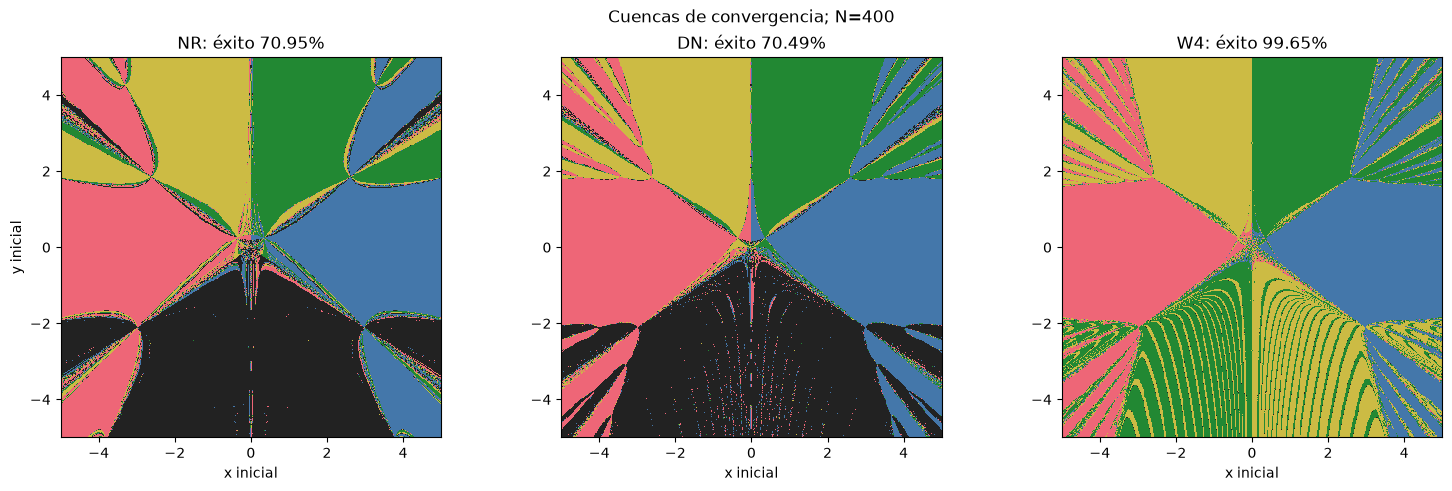

In [13]:
x_mapa, y_mapa = make_mesh(N_MAPA)
BASE_RESULTS = {m: REFINEMENT_RESULTS[(N_MAPA, m)] for m in ("NR", "DN", "W4")}
BASE_ROWS = [resumen_cuenca(BASE_RESULTS[m], m, N_MAPA,
                            paso_metodo(m), P0_BASE)
             for m in ("NR", "DN", "W4")]
df_cuencas = pd.DataFrame(BASE_ROWS)
df_cuencas.to_csv(RESULTS_DIR / "colab_basin_summary.csv", index=False)

# Participaciones de R1--R4 se calculan sobre todos los nodos, no solo los éxitos.
display(df_cuencas[["resolution", "method", "points", "success_pct", "R1_pct", "R2_pct",
                    "R3_pct", "R4_pct", "mean_iterations_converged", "diverged",
                    "max_iterations", "singular_jacobian", "udl_pivot_failure"]])

colores = ["#4477AA", "#EE6677", "#228833", "#CCBB44", "#222222"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), constrained_layout=True)
extent = [DOMINIO[0], DOMINIO[1], DOMINIO[0], DOMINIO[1]]
for ax, metodo in zip(axes, ("NR", "DN", "W4")):
    r = BASE_RESULTS[metodo]
    etiquetas = np.where(r.statuses == Status.CONVERGED, r.roots, 4)
    ax.imshow(etiquetas, origin="lower", extent=extent, interpolation="nearest",
              cmap=plt.matplotlib.colors.ListedColormap(colores), vmin=0, vmax=4)
    exito = 100.0 * np.mean(r.statuses == Status.CONVERGED)
    ax.set_title("%s: éxito %.2f%%" % (metodo, exito))
    ax.set_xlabel("x inicial")
    ax.set_aspect("equal")
axes[0].set_ylabel("y inicial")
fig.suptitle("Cuencas de convergencia; N=%d" % N_MAPA)
fig.savefig(RESULTS_DIR / "figura_1_cuencas.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

La superposición corresponde a la Figura 4 del informe: usa las cuencas W4 como fondo y marca en dos paneles los nodos donde NR y DN fallan. El encuadre resalta el sector central-superior para hacer visible la coincidencia espacial.

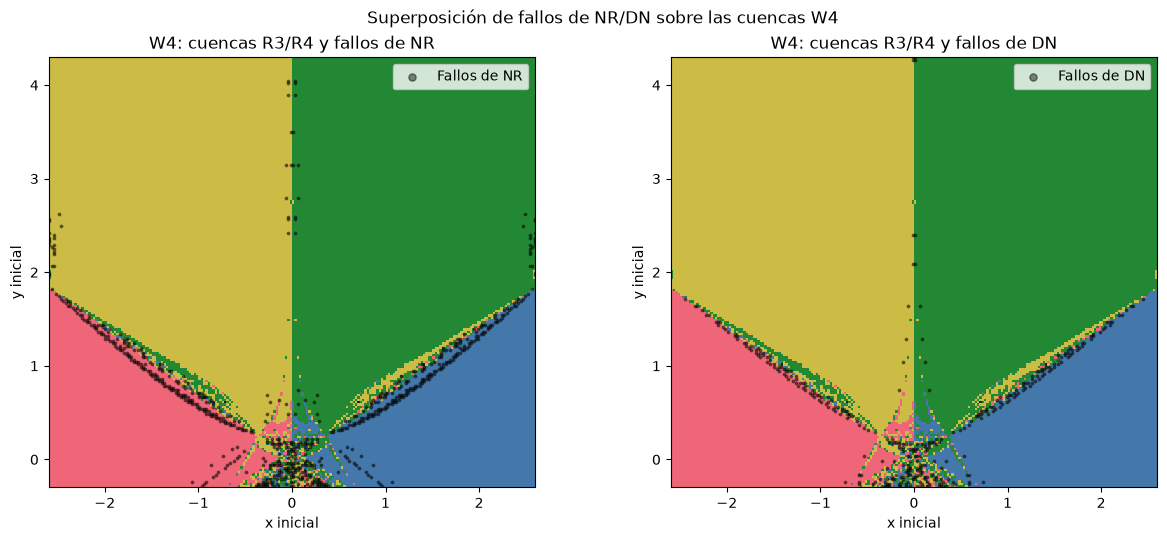

In [14]:
w4 = BASE_RESULTS["W4"]
etiquetas_w4 = np.where(w4.statuses == Status.CONVERGED, w4.roots, 4)
fig, axes = plt.subplots(1, 2, figsize=(12.4, 5.3), constrained_layout=True)
cmap = plt.matplotlib.colors.ListedColormap(colores)
for ax, metodo in zip(axes, ("NR", "DN")):
    ax.imshow(etiquetas_w4, origin="lower", extent=extent, interpolation="nearest",
              cmap=cmap, vmin=0, vmax=4)
    fallidos = BASE_RESULTS[metodo].statuses != Status.CONVERGED
    ax.scatter(x_mapa[fallidos], y_mapa[fallidos], s=3, color="black", alpha=0.45,
               label="Fallos de " + metodo)
    ax.set_title("W4: cuencas R3/R4 y fallos de " + metodo)
    ax.set_xlabel("x inicial")
    ax.set_ylabel("y inicial")
    ax.set_xlim(-2.6, 2.6)
    ax.set_ylim(-0.3, 4.3)
    ax.set_aspect("equal")
    ax.legend(loc="upper right", markerscale=3)
    ax.grid(False)
fig.suptitle("Superposición de fallos de NR/DN sobre las cuencas W4")
fig.savefig(RESULTS_DIR / "figura_2_superposicion.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

## 9. Sensibilidad a `Δτ`, `α` y `p0`

El barrido compara DN (`α`) y W4 (`Δτ`) en la misma malla determinista. En modo completo se usa N=200 y los cinco pasos del estudio. La sensibilidad de momento usa W4, N=100 y perturbaciones deterministas de `p0`; `p0=(0,0)` es un supuesto del equipo para el problema multidimensional.

In [15]:
TAU_ROWS = []
x_tau, y_tau = make_mesh(N_BARRIDO)
for metodo in ("DN", "W4"):
    for tau in TAUS:
        r = solve_basin(metodo, x_tau, y_tau, step=tau, tolerance=TOLERANCIA,
                        max_iterations=MAX_ITER, divergence_limit=LIMITE_DIVERGENCIA,
                        singular_rtol=TOL_SINGULAR_REL, p0=P0_BASE)
        row = resumen_cuenca(r, metodo, N_BARRIDO, tau, P0_BASE)
        row["parameter"] = "alpha" if metodo == "DN" else "delta_tau"
        TAU_ROWS.append(row)
df_tau = pd.DataFrame(TAU_ROWS)
df_tau.to_csv(RESULTS_DIR / "colab_tau_sensitivity.csv", index=False)
display(df_tau[["parameter", "method", "step", "success_pct", "R1_pct", "R2_pct",
                "R3_pct", "R4_pct", "mean_iterations_converged", "diverged",
                "max_iterations", "udl_pivot_failure"]])

P0_ROWS = []
x_p0, y_p0 = make_mesh(N_BASE if MODO_COMPLETO else N_VALIDACION)
for p0 in P0_CASOS:
    r = solve_basin("W4", x_p0, y_p0, step=DELTA_TAU, tolerance=TOLERANCIA,
                    max_iterations=MAX_ITER, divergence_limit=LIMITE_DIVERGENCIA,
                    singular_rtol=TOL_SINGULAR_REL, p0=p0)
    row = resumen_cuenca(r, "W4", x_p0.shape[0], DELTA_TAU, p0)
    P0_ROWS.append(row)
df_p0 = pd.DataFrame(P0_ROWS)
df_p0.to_csv(RESULTS_DIR / "colab_p0_sensitivity.csv", index=False)
display(df_p0[["p0x", "p0y", "success_pct", "R1_pct", "R2_pct", "R3_pct", "R4_pct",
               "mean_iterations_converged", "diverged", "udl_pivot_failure"]])

,parameter,method,step,success_pct,R1_pct,R2_pct,R3_pct,R4_pct,mean_iterations_converged,diverged,max_iterations,udl_pivot_failure
0,alpha,DN,0.10,74.1900,21.9050,21.8950,15.2050,15.1850,162.289190,1,10323,0
1,alpha,DN,0.25,71.9350,20.8225,20.8300,15.1375,15.1450,59.783172,1,11225,0
2,alpha,DN,0.50,70.5150,20.1050,20.1000,15.1550,15.1550,25.739027,1,11793,0
3,alpha,DN,0.75,70.4525,20.0825,20.0850,15.1400,15.1450,14.066570,7,11812,0
4,alpha,DN,0.90,70.5150,20.0900,20.0925,15.1650,15.1675,9.670177,1,11793,0
5,delta_tau,W4,0.10,99.3950,20.0200,20.0225,29.6800,29.6725,284.586020,156,0,86
6,delta_tau,W4,0.25,99.4450,20.1850,20.1950,29.5325,29.5325,107.696139,180,0,42
7,delta_tau,W4,0.50,99.6500,20.5925,20.5900,29.2300,29.2375,50.432790,134,0,6
8,delta_tau,W4,0.75,88.4225,20.8975,20.8925,23.3125,23.3200,31.041958,4169,0,462
9,delta_tau,W4,0.90,71.5450,19.5075,19.5050,16.2625,16.2700,19.491544,11261,0,121


,p0x,p0y,success_pct,R1_pct,R2_pct,R3_pct,R4_pct,mean_iterations_converged,diverged,udl_pivot_failure
0,0.00,0.00,99.64,20.44,20.45,29.36,29.39,50.672621,34,2
1,0.05,0.00,99.68,20.81,20.06,29.98,28.83,51.057785,32,0
2,-0.05,0.00,99.68,20.05,20.82,28.84,29.97,51.063503,32,0
3,0.00,0.05,99.54,20.35,20.35,29.41,29.43,50.808117,44,2
4,0.00,-0.05,99.64,20.47,20.46,29.35,29.36,50.583200,36,0


## 10. Orden y tasa local; valor propio doble de W4

Las tasas usan el error de posición `e_n=||x_n−x*||₂` respecto a una raíz analítica; es distinto del residuo usado para detener el método. El orden de NR se estima con `q=log(e[n+2]/e[n+1])/log(e[n+1]/e[n])`; para DN y W4 se comparan las razones `e[n+1]/e[n]`.

Sea `h=Δτ`. Al linealizar W4 en `(x*,0)` y usar `XY=J⁻¹`, se obtiene `A=[[I,hX],[-hX⁻¹,(1−2h)I]]=(1−h)I+N`, donde `N²=0`. Así, `Aⁿ=(1−h)ⁿI+n(1−h)ⁿ⁻¹N→0` para `0<h<1`; el bloque defectivo puede producir el factor polinómico `n`, pero el error decrece con razón asintótica `1−h`. DN con factor fijo tiene derivada `(1−α)I` en la raíz y tasa lineal `1−α`. NR tiene orden local dos si `F` es suficientemente suave y el Jacobiano en la raíz es no singular. La tabla y figura contrastan estas predicciones con diferencias finitas y trayectorias cercanas a raíces; son mediciones locales, no implican convergencia global.

In [16]:
def mapa_w4_estado(estado, step):
    x, y, p, q = [np.array([v], dtype=np.float64) for v in estado]
    f1, f2 = evaluate(x, y)
    xn, yn, pn, qn = w4_update(x, y, p, q, f1, f2, step, C_FRICTION)
    return np.array([xn[0], yn[0], pn[0], qn[0]])

FD_ROWS = []
for i, raiz in enumerate(RAICES):
    estado = np.array([raiz[0], raiz[1], 0.0, 0.0])
    h = 1e-5
    jac = np.empty((4, 4))
    for j in range(4):
        delta = np.zeros(4)
        delta[j] = h
        jac[:, j] = (mapa_w4_estado(estado + delta, DELTA_TAU)
                     - mapa_w4_estado(estado - delta, DELTA_TAU)) / (2.0 * h)
    radio = float(np.max(np.abs(np.linalg.eigvals(jac))))
    FD_ROWS.append({"raíz": "R%d" % (i + 1), "ρ FD W4": radio,
                    "1−Δτ": 1.0 - DELTA_TAU, "error abs.": abs(radio - (1.0 - DELTA_TAU))})
df_fd = pd.DataFrame(FD_ROWS)

RATE_ROWS = []
RATE_SCALE_ROWS = []
BANDAS_ERROR = ((1e-4, 1e-5), (1e-5, 1e-6), (1e-6, 1e-7),
                (1e-7, 1e-8), (1e-8, 1e-9), (1e-9, 1e-10),
                (1e-10, 1e-11), (1e-11, 1e-12))
for metodo, paso in (("DN", ALPHA), ("W4", DELTA_TAU)):
    ratios, by_band = [], {band: [] for band in BANDAS_ERROR}
    for raiz in RAICES:
        tr = trace_point(metodo, float(raiz[0] + 0.25), float(raiz[1] - 0.175),
                         step=paso, tolerance=1e-15, max_iterations=120,
                         divergence_limit=LIMITE_DIVERGENCIA,
                         singular_rtol=TOL_SINGULAR_REL, p0=P0_BASE)
        errores = np.hypot(tr.x - raiz[0], tr.y - raiz[1])
        rr = errores[1:] / errores[:-1]
        for k, valor in enumerate(rr):
            if 1e-11 < errores[k] < 1e-7 and np.isfinite(valor):
                ratios.append(float(valor))
            for upper, lower in BANDAS_ERROR:
                if lower < errores[k] <= upper and np.isfinite(valor):
                    by_band[(upper, lower)].append(float(valor))
                    break
    RATE_ROWS.append({"método": metodo, "tasa teórica": 1.0 - paso,
                      "muestras": len(ratios), "mediana e[n+1]/e[n]": np.median(ratios),
                      "mínimo": np.min(ratios), "máximo": np.max(ratios)})
    for upper, lower in BANDAS_ERROR:
        values = by_band[(upper, lower)]
        RATE_SCALE_ROWS.append({"método": metodo, "error entre": "%g y %g" % (upper, lower),
                                "muestras": len(values),
                                "mediana razón": np.median(values) if values else np.nan})
df_rates = pd.DataFrame(RATE_ROWS)
df_rate_scales = pd.DataFrame(RATE_SCALE_ROWS)
df_fd.to_csv(RESULTS_DIR / "colab_w4_fd_spectrum.csv", index=False)
df_rates.to_csv(RESULTS_DIR / "colab_local_rates.csv", index=False)
display(df_fd)
display(df_rates)

OFFSETS_ORDEN = ((0.25, -0.175), (0.30, -0.21), (0.35, -0.245), (0.40, -0.28))
def triples_orden(errors):
    out = []
    for a, b, c in zip(errors[:-2], errors[1:-1], errors[2:]):
        if 1e-14 < c < b < a and b < 1e-2:
            den = np.log(b / a)
            if den != 0.0:
                out.append(float(np.log(c / b) / den))
    return out

ORDER_ROWS = []
for rid, raiz in enumerate(RAICES):
    values = []
    for desplazamiento in OFFSETS_ORDEN:
        tr = trace_point("NR", float(raiz[0] + desplazamiento[0]),
                         float(raiz[1] + desplazamiento[1]), step=1.0,
                         tolerance=1e-15, max_iterations=80,
                         divergence_limit=LIMITE_DIVERGENCIA,
                         singular_rtol=TOL_SINGULAR_REL)
        values.extend(triples_orden(np.hypot(tr.x - raiz[0], tr.y - raiz[1])))
    ORDER_ROWS.append({"raíz": "R%d" % (rid + 1), "triples": len(values),
                       "mediana q": np.median(values), "mínimo q": np.min(values),
                       "máximo q": np.max(values)})
df_orden = pd.DataFrame(ORDER_ROWS)
df_orden.to_csv(RESULTS_DIR / "colab_nr_local_order.csv", index=False)
display(df_orden)

,raíz,ρ FD W4,1−Δτ,error abs.
0,R1,0.500001,0.5,0.000001
1,R2,0.500001,0.5,0.000001
2,R3,0.500002,0.5,0.000002
3,R4,0.500002,0.5,0.000002


,método,tasa teórica,muestras,mediana e[n+1]/e[n],mínimo,máximo
0,DN,0.5,53,0.500000,0.499969,0.500003
1,W4,0.5,56,0.515713,0.512588,0.521107


,raíz,triples,mediana q,mínimo q,máximo q
0,R1,8,1.992020,1.960713,2.000054
1,R2,7,2.005452,1.942035,2.016100
2,R3,6,1.972878,1.959798,2.002003
3,R4,7,1.996230,1.957429,2.000609


## 11. Diagnóstico de fallos y trayectorias ilustrativas

Las trayectorias se eligen determinísticamente de la malla para ilustrar NR agotado, fallos compartidos y un fallo mixto; no son una muestra estadística. W4 registra la distancia mínima de **cada trayectoria** a `x=0` y `x²=2y²`. Se reportan medianas, máximos y conteos con el umbral `1e-3`; una mediana no es una cota para todas las trayectorias. Se separan éxito, divergencia y pivote UDL y se conserva la comparación espacial de fallos NR/DN con la región W4 R3/R4.

,punto,x0,y0,método,estado,iteraciones,criterio,norma JTF último estado finito
0,1,2.669173,-2.568922,NR,max_iterations,1000,menor residuo final NR agotado / W4 converge,2.000000e+00
1,1,2.669173,-2.568922,DN,max_iterations,1000,menor residuo final NR agotado / W4 converge,2.152038e+00
2,1,2.669173,-2.568922,W4,converged,84,menor residuo final NR agotado / W4 converge,2.106520e-06
3,2,-2.443609,-5.000000,NR,max_iterations,1000,iteraciones W4 más cercanas a la mediana entre...,3.172967e+01
4,2,-2.443609,-5.000000,DN,max_iterations,1000,iteraciones W4 más cercanas a la mediana entre...,2.000107e+00
5,2,-2.443609,-5.000000,W4,converged,83,iteraciones W4 más cercanas a la mediana entre...,3.613908e-06
6,3,4.473684,-3.170426,NR,max_iterations,1000,posición lexicográfica mediana entre fallos mi...,1.633378e+04
7,3,4.473684,-3.170426,DN,diverged,54,posición lexicográfica mediana entre fallos mi...,1.856553e+26
8,3,4.473684,-3.170426,W4,converged,123,posición lexicográfica mediana entre fallos mi...,2.541719e-06


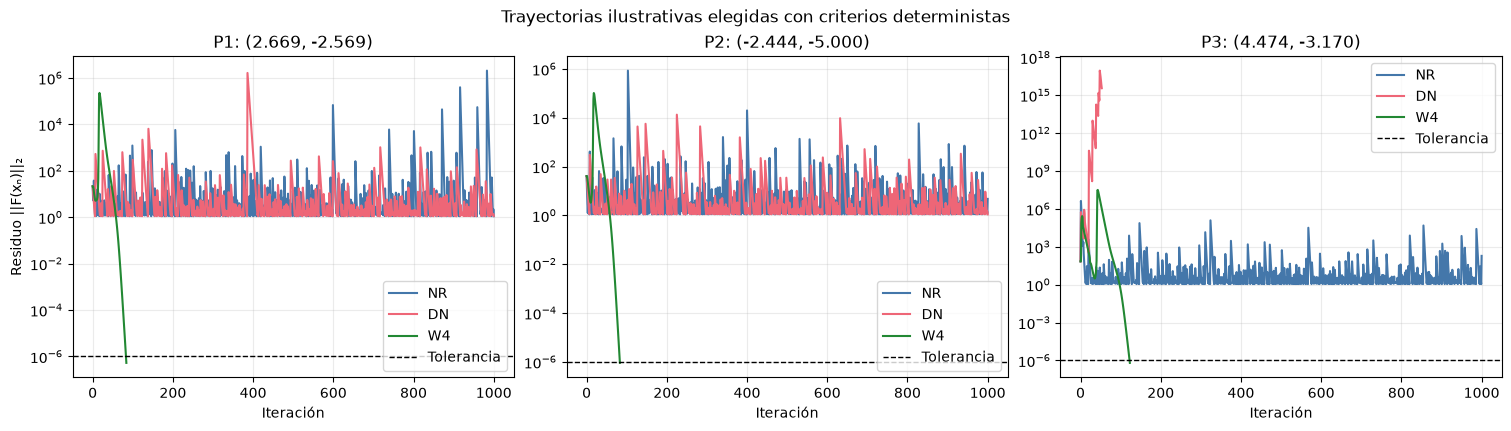

,grupo,trayectorias,mediana distancia x=0,mediana distancia x²=2y²,mediana distancia unión,máxima distancia mínima unión,trayectorias d_min >= 1e-3,fracción <1e-3 (%),"fracción ≤0,025 (%)","fracción ≤0,1 (%)"
0,todas,160000,0.733077,0.605391,0.175951,0.937870,159004,0.622500,13.970625,41.332500
1,éxito,159440,0.733077,0.604994,0.178068,0.937870,159000,0.275966,13.668465,41.126443
2,divergencia,548,0.000426,0.743364,0.000424,0.001394,4,99.270073,100.000000,100.000000
3,pivote UDL,12,0.000144,1.174730,0.000144,0.000534,0,100.000000,100.000000,100.000000
4,agotó,0,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN


,método,nodos W4 R3/R4,fallos totales del método,fallos dentro de W4 R3/R4,% de fallos del método en W4 R3/R4
0,NR,93914,46487,41996,90.339235
1,DN,93914,47217,42357,89.707097


,método,agotados,residuo final mínimo
0,NR,46472,1.106152
1,DN,47212,1.106152


In [17]:
def elegir_inicios_ilustrativos(x0, y0, resultados):
    nr, dn, w4 = resultados["NR"], resultados["DN"], resultados["W4"]
    exhausted = (nr.statuses == Status.MAX_ITERATIONS) & (w4.statuses == Status.CONVERGED)
    selected = []
    candidates = np.argwhere(exhausted)
    if candidates.size:
        flat = np.ravel_multi_index(candidates.T, exhausted.shape)
        residual = nr.residuals.ravel()[flat]
        keys_x = x0.ravel()[flat]
        keys_y = y0.ravel()[flat]
        order = np.lexsort((keys_y, keys_x, residual))
        rc = tuple(int(v) for v in candidates[order[0]])
        selected.append((rc, "menor residuo final NR agotado / W4 converge"))
    both_fail = ((nr.statuses != Status.CONVERGED) & (dn.statuses != Status.CONVERGED)
                 & (w4.statuses == Status.CONVERGED))
    candidates = np.argwhere(both_fail)
    if candidates.size and len(selected) < 2:
        work = w4.iterations[both_fail]
        target = np.median(work)
        order = np.lexsort((candidates[:, 1], candidates[:, 0], np.abs(work - target)))
        rc = tuple(int(v) for v in candidates[order[0]])
        if rc not in [item[0] for item in selected]:
            selected.append((rc, "iteraciones W4 más cercanas a la mediana entre fallos NR/DN"))
    mixed = (((nr.statuses == Status.DIVERGED) & (dn.statuses == Status.MAX_ITERATIONS))
             | ((dn.statuses == Status.DIVERGED) & (nr.statuses == Status.MAX_ITERATIONS)))
    mixed &= w4.statuses == Status.CONVERGED
    candidates = np.argwhere(mixed)
    if candidates.size and len(selected) < 3:
        rc = tuple(int(v) for v in candidates[len(candidates) // 2])
        if rc not in [item[0] for item in selected]:
            selected.append((rc, "posición lexicográfica mediana entre fallos mixtos y éxito W4"))
    return selected

INICIOS_ILUSTRATIVOS = elegir_inicios_ilustrativos(x_mapa, y_mapa, BASE_RESULTS)
TRACE_ROWS, TRACE_META = [], []
for point_id, (rc, razon) in enumerate(INICIOS_ILUSTRATIVOS, 1):
    row, col = rc
    xi, yi = float(x_mapa[row, col]), float(y_mapa[row, col])
    for metodo in ("NR", "DN", "W4"):
        paso = paso_metodo(metodo)
        tr = trace_point(metodo, xi, yi, step=paso, tolerance=TOLERANCIA,
                         max_iterations=MAX_ITER, divergence_limit=LIMITE_DIVERGENCIA,
                         singular_rtol=TOL_SINGULAR_REL, p0=P0_BASE)
        grad_norm = np.nan
        if tr.x.size:
            xf, yf = float(tr.x[-1]), float(tr.y[-1])
            f_final = np.array(evaluate(xf, yf))
            j_final = np.array(jacobian_entries(xf, yf)).reshape(2, 2)
            grad_norm = float(np.linalg.norm(j_final.T @ f_final))
        TRACE_META.append({"punto": point_id, "x0": xi, "y0": yi,
                           "método": metodo, "estado": tr.status,
                           "iteraciones": tr.iterations, "criterio": razon,
                           "norma JTF último estado finito": grad_norm})
        for k, residuo in enumerate(tr.residual):
            TRACE_ROWS.append({"punto": point_id, "método": metodo,
                               "iteración": k, "residuo": float(residuo),
                               "x": float(tr.x[k]), "y": float(tr.y[k])})
df_trazas = pd.DataFrame(TRACE_ROWS)
df_traza_meta = pd.DataFrame(TRACE_META)
df_traza_meta.to_csv(RESULTS_DIR / "colab_illustrative_trajectory_summary.csv", index=False)
df_trazas.to_csv(RESULTS_DIR / "colab_illustrative_trajectories.csv", index=False)
display(df_traza_meta)

fig, axes = plt.subplots(1, max(1, len(INICIOS_ILUSTRATIVOS)),
                         figsize=(5.0 * max(1, len(INICIOS_ILUSTRATIVOS)), 4.2),
                         squeeze=False, constrained_layout=True)
colores_metodo = {"NR": "#4477AA", "DN": "#EE6677", "W4": "#228833"}
for ax, point_id in zip(axes[0], range(1, len(INICIOS_ILUSTRATIVOS) + 1)):
    for metodo in ("NR", "DN", "W4"):
        subset = df_trazas[(df_trazas["punto"] == point_id) & (df_trazas["método"] == metodo)]
        ax.semilogy(subset["iteración"], np.maximum(subset["residuo"], 1e-18),
                    color=colores_metodo[metodo], label=metodo)
    ax.set_title("P%d: (%.3f, %.3f)" % (point_id,
                 df_traza_meta[df_traza_meta["punto"] == point_id].iloc[0]["x0"],
                 df_traza_meta[df_traza_meta["punto"] == point_id].iloc[0]["y0"]))
    ax.axhline(TOLERANCIA, color="black", linestyle="--", linewidth=1, label="Tolerancia")
    ax.set_xlabel("Iteración")
    ax.grid(True, which="both", alpha=0.25)
    ax.legend()
axes[0, 0].set_ylabel("Residuo ||F(xₙ)||₂")
fig.suptitle("Trayectorias ilustrativas elegidas con criterios deterministas")
fig.savefig(RESULTS_DIR / "figura_3_trayectorias.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

# La distancia se calcula durante todos los estados finitos acotados de W4.
w4_base = BASE_RESULTS["W4"]
assert w4_base.minimum_distance_singular_union is not None
path_masks = {
    "todas": np.ones(w4_base.statuses.shape, dtype=bool),
    "éxito": w4_base.statuses == Status.CONVERGED,
    "divergencia": w4_base.statuses == Status.DIVERGED,
    "pivote UDL": w4_base.statuses == Status.UDL_PIVOT_FAILURE,
    "agotó": w4_base.statuses == Status.MAX_ITERATIONS,
}
path_union = w4_base.minimum_distance_singular_union
path_x0 = w4_base.minimum_distance_x0
path_diag = w4_base.minimum_distance_diagonal
PATH_ROWS = []
for categoria, mask in path_masks.items():
    count = int(np.count_nonzero(mask))
    PATH_ROWS.append({
        "grupo": categoria, "trayectorias": count,
        "mediana distancia x=0": float(np.median(path_x0[mask])) if count else np.nan,
        "mediana distancia x²=2y²": float(np.median(path_diag[mask])) if count else np.nan,
        "mediana distancia unión": float(np.median(path_union[mask])) if count else np.nan,
        "máxima distancia mínima unión": float(np.max(path_union[mask])) if count else np.nan,
        "trayectorias d_min >= 1e-3": int(np.count_nonzero(path_union[mask] >= 1e-3)),
        "fracción <1e-3 (%)": 100.0 * np.count_nonzero(path_union[mask] < 1e-3) / count if count else np.nan,
        "fracción ≤0,025 (%)": 100.0 * np.count_nonzero(path_union[mask] <= 0.025) / count if count else np.nan,
        "fracción ≤0,1 (%)": 100.0 * np.count_nonzero(path_union[mask] <= 0.1) / count if count else np.nan,
    })
df_path = pd.DataFrame(PATH_ROWS)
df_path.to_csv(RESULTS_DIR / "colab_w4_path_distance_summary.csv", index=False)
all_path_rows = pd.DataFrame({
    "x inicial": x_mapa.ravel(), "y inicial": y_mapa.ravel(),
    "estado": w4_base.statuses.ravel(), "iteraciones": w4_base.iterations.ravel(),
    "mínima a x=0": path_x0.ravel(), "mínima a x²=2y²": path_diag.ravel(),
    "mínima a unión singular": path_union.ravel(),
})
all_path_rows.to_csv(RESULTS_DIR / "colab_w4_path_min_distances.csv", index=False)
display(df_path)

# Fallos NR/DN dentro de la región donde W4 asigna R3 o R4.
region_w4_34 = ((w4_base.statuses == Status.CONVERGED)
                & np.isin(w4_base.roots, (2, 3)))
OVERLAP_ROWS = []
for metodo in ("NR", "DN"):
    failed = BASE_RESULTS[metodo].statuses != Status.CONVERGED
    inside = region_w4_34 & failed
    OVERLAP_ROWS.append({"método": metodo, "nodos W4 R3/R4": int(region_w4_34.sum()),
                         "fallos totales del método": int(failed.sum()),
                         "fallos dentro de W4 R3/R4": int(inside.sum()),
                         "% de fallos del método en W4 R3/R4":
                         100.0 * inside.sum() / failed.sum() if failed.sum() else np.nan})
df_overlap = pd.DataFrame(OVERLAP_ROWS)
df_overlap.to_csv(RESULTS_DIR / "colab_failure_overlap.csv", index=False)
display(df_overlap)

# Residuos mínimos de los puntos agotados de NR y DN; esto no prueba que haya ciclos.
EXHAUSTION_ROWS = []
for metodo in ("NR", "DN"):
    r = BASE_RESULTS[metodo]
    mask = r.statuses == Status.MAX_ITERATIONS
    EXHAUSTION_ROWS.append({"método": metodo, "agotados": int(mask.sum()),
                            "residuo final mínimo": float(np.min(r.residuals[mask])) if np.any(mask) else np.nan})
df_agotados = pd.DataFrame(EXHAUSTION_ROWS)
df_agotados.to_csv(RESULTS_DIR / "colab_exhausted_summary.csv", index=False)
display(df_agotados)

## 12. Costo de actualización, conjunto común y sensibilidad al tope

Se mide tiempo transcurrido con `time.perf_counter()`. Para cada método, `c_m` es la mediana en microsegundos por punto-iteración; el microbenchmark procesa un lote determinista de 10 000 puntos durante 250 actualizaciones, con 3 calentamientos y 30 repeticiones. Cada punto-iteración incluye evaluar `F` y aplicar la actualización. La estimación de costo amortizado es `C_m = c_m × (Σ_i k_i) / S_m`: `k_i` cuenta las actualizaciones de cada intento, también los que fallan, y `S_m` cuenta los puntos que sí devolvieron raíz. La unidad es µs por raíz devuelta. No incluye todo el costo de clasificación, control y almacenamiento, y depende del hardware.

La comparación de iteraciones en el conjunto común usa los 106 405 inicios en que convergen los tres métodos; es una comparación condicionada a los mismos casos resueltos. La sensibilidad al tope reconstruye el trabajo hasta cada máximo contando también los nodos que no devuelven raíz. Por ello, el costo por raíz cambia con el tope y la tasa de éxito; las cifras no afirman que W4 cueste menos en general.

Microbenchmark para las estimaciones de costo:


,método,puntos lote,iteraciones fijas,calentamientos,repeticiones,mínimo (s),mediana (s),mínimo µs/punto-iter,mediana µs/punto-iter
0,NR,10000,250,3,30,0.085383,0.113157,0.034153,0.045263
1,DN,10000,250,3,30,0.092865,0.120041,0.037146,0.048016
2,W4,10000,250,3,30,0.125423,0.167145,0.050169,0.066858


Costo propio, conjunto común y costo amortizado de la malla:


,método,éxito propio (%),iteraciones éxito propio,iteraciones conjunto común,µs por actualización,µs por trayectoria propia,µs por trayectoria común,µs por raíz amortizado malla
0,NR,70.945625,5.980381,5.820215,0.045263,0.270689,0.263440,18.803858
1,DN,70.489375,25.756541,25.481434,0.048016,1.236739,1.223529,21.338060
2,W4,99.650000,50.530576,37.488088,0.066858,3.378367,2.506374,3.382179


Nodos del conjunto común: 106405
Sensibilidad al máximo de iteraciones (Tabla 8 del informe):


éxito (%)                       µs/raíz amortizado             \
método         DN         NR         W4                 DN         NR   
tope                                                                    
10       0.000000  68.087500   0.000000                NaN   0.466319   
20       2.277500  70.683750   0.007500          42.150265   0.642796   
50      70.247500  70.943750  67.996250           2.247371   1.197538   
100     70.479375  70.945625  96.084375           3.247312   2.124313   
200     70.489375  70.945625  99.638750           5.257132   3.977816   
500     70.489375  70.945625  99.650000          11.287675   9.538032   
1000    70.489375  70.945625  99.650000          21.338060  18.803858   

                      
método            W4  
tope                  
10               NaN  
20      17810.604938  
50          3.909348  
100         3.474362  
200         3.382396  
500         3.382179  
1000        3.382179

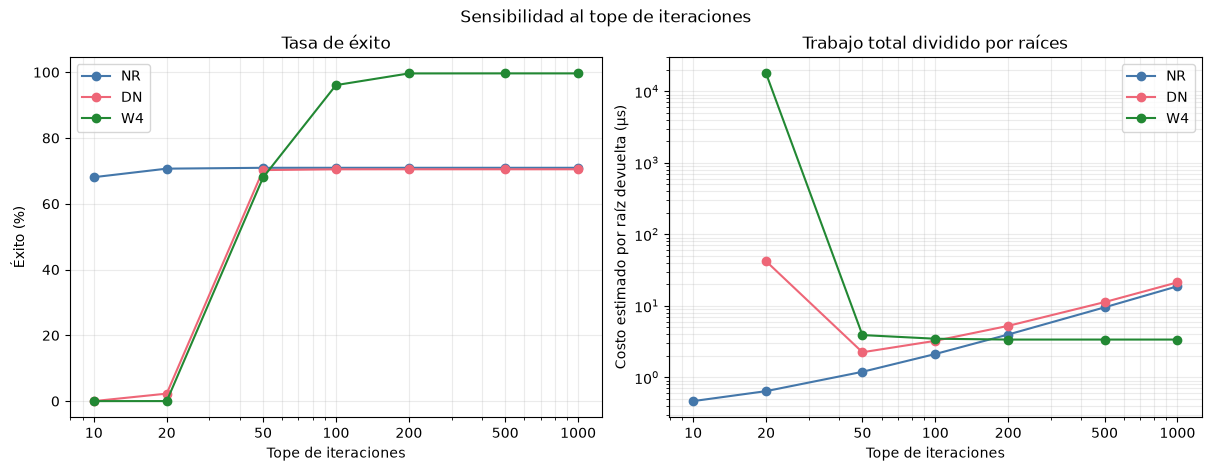

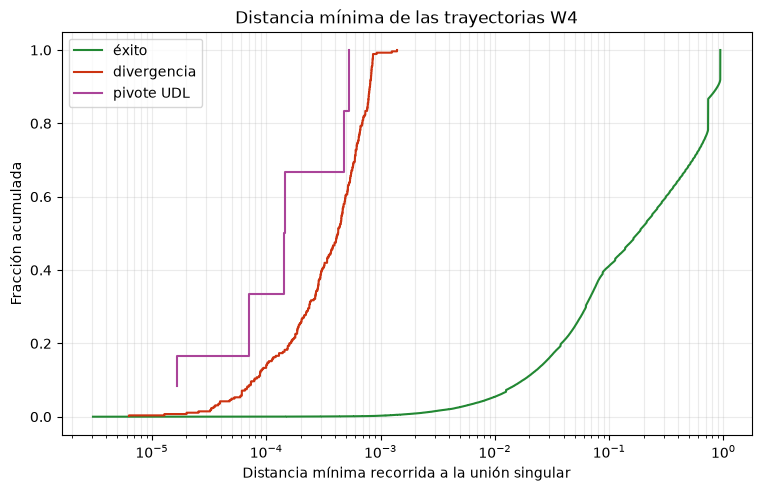

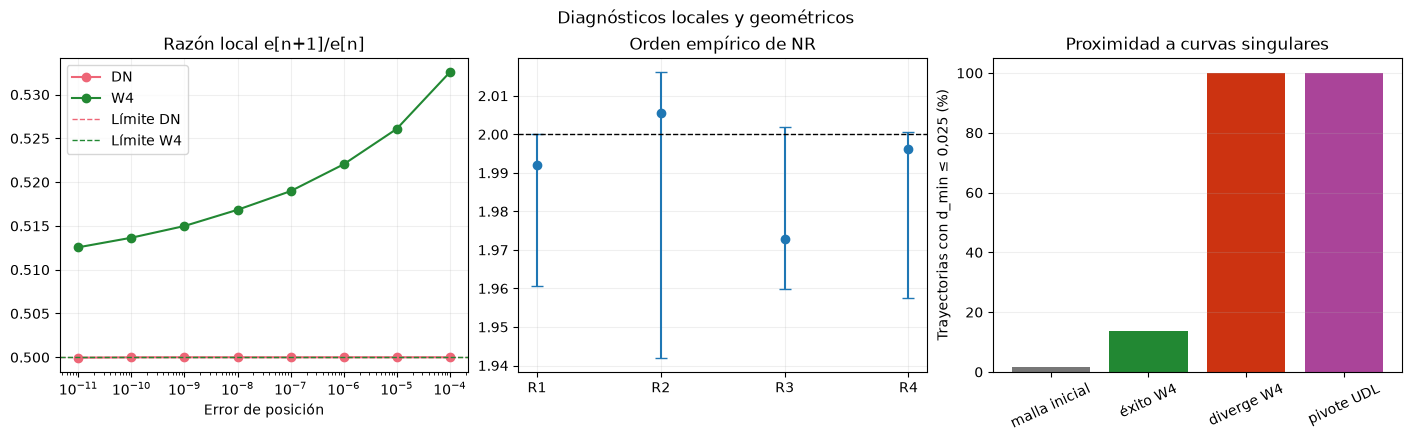

In [18]:
def puntos_microbenchmark(lado):
    offsets = np.linspace(-0.01, 0.01, lado)
    dx, dy = np.meshgrid(offsets, offsets, indexing="xy")
    return (np.concatenate([root[0] + dx.ravel() for root in RAICES]),
            np.concatenate([root[1] + dy.ravel() for root in RAICES]))

def ejecutar_trabajo_fijo(metodo, x0, y0, iterations, step):
    x, y = x0.copy(), y0.copy()
    p, q = np.full_like(x, P0_BASE[0]), np.full_like(y, P0_BASE[1])
    with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
        for _ in range(iterations):
            f1, f2 = evaluate(x, y)
            if metodo == "NR":
                x, y = nr_update(x, y, f1, f2)
            elif metodo == "DN":
                x, y = dn_update(x, y, f1, f2, step)
            else:
                x, y, p, q = w4_update(x, y, p, q, f1, f2, step, C_FRICTION)
    return x, y

x_micro, y_micro = puntos_microbenchmark(LADO_MICRO)
MICRO_ROWS = []
durations = {m: [] for m in ("NR", "DN", "W4")}
for metodo in ("NR", "DN", "W4"):
    paso = paso_metodo(metodo)
    for _ in range(CALENTAMIENTOS_MICRO):
        ejecutar_trabajo_fijo(metodo, x_micro, y_micro, ITER_MICRO, paso)
for repeticion in range(REP_MICRO):
    orden = ["NR", "DN", "W4"]
    corte = repeticion % len(orden)
    orden = orden[corte:] + orden[:corte]
    for metodo in orden:
        paso = paso_metodo(metodo)
        t0 = time.perf_counter()
        xf, yf = ejecutar_trabajo_fijo(metodo, x_micro, y_micro, ITER_MICRO, paso)
        dur = time.perf_counter() - t0
        assert np.all(np.isfinite(xf)) and np.all(np.isfinite(yf)), metodo
        durations[metodo].append(dur)
for metodo in ("NR", "DN", "W4"):
    samples = np.asarray(durations[metodo])
    point_iterations = x_micro.size * ITER_MICRO
    MICRO_ROWS.append({"método": metodo, "puntos lote": x_micro.size,
                       "iteraciones fijas": ITER_MICRO, "calentamientos": CALENTAMIENTOS_MICRO,
                       "repeticiones": REP_MICRO, "mínimo (s)": float(np.min(samples)),
                       "mediana (s)": float(np.median(samples)),
                       "mínimo µs/punto-iter": float(np.min(samples) * 1e6 / point_iterations),
                       "mediana µs/punto-iter": float(np.median(samples) * 1e6 / point_iterations)})
df_micro = pd.DataFrame(MICRO_ROWS)
df_micro.to_csv(RESULTS_DIR / "colab_fixed_work_microbenchmark.csv", index=False)
print("Microbenchmark para las estimaciones de costo:")
display(df_micro)

# Comparación en éxitos propios, subconjunto común y malla completa.
common_mask = np.logical_and.reduce([
    BASE_RESULTS[m].statuses == Status.CONVERGED for m in ("NR", "DN", "W4")
])
bench_per_update = {r["método"]: r["mediana µs/punto-iter"] for r in MICRO_ROWS}
COST_ROWS = []
for metodo in ("NR", "DN", "W4"):
    r = BASE_RESULTS[metodo]
    success = r.statuses == Status.CONVERGED
    n_success = int(success.sum())
    mean_own = float(np.mean(r.iterations[success])) if n_success else np.nan
    mean_common = float(np.mean(r.iterations[common_mask])) if np.any(common_mask) else np.nan
    unit = bench_per_update[metodo]
    total_updates = int(np.sum(r.iterations, dtype=np.int64))
    COST_ROWS.append({"método": metodo,
                      "éxito propio (%)": 100.0 * n_success / r.statuses.size,
                      "iteraciones éxito propio": mean_own,
                      "iteraciones conjunto común": mean_common,
                      "µs por actualización": unit,
                      "µs por trayectoria propia": unit * mean_own,
                      "µs por trayectoria común": unit * mean_common,
                      "µs por raíz amortizado malla": unit * total_updates / n_success if n_success else np.nan})
df_cost = pd.DataFrame(COST_ROWS)
df_cost.to_csv(RESULTS_DIR / "colab_cost_comparison.csv", index=False)
print("Costo propio, conjunto común y costo amortizado de la malla:")
display(df_cost)
print("Nodos del conjunto común:", int(common_mask.sum()))

# Sensibilidad al tope: los historiales terminales de la corrida base se truncan por tope.
CAP_ROWS = []
for cap in TOPE_SENSIBILIDAD:
    for metodo in ("NR", "DN", "W4"):
        r = BASE_RESULTS[metodo]
        it = r.iterations.ravel().astype(np.int64)
        status = r.statuses.ravel()
        success = (status == Status.CONVERGED) & (it <= cap)
        count = int(success.sum())
        work = int(np.minimum(it, cap).sum())
        CAP_ROWS.append({"tope": cap, "método": metodo,
                         "éxito (%)": 100.0 * count / it.size,
                         "éxitos": count, "trabajo total puntos-iter": work,
                         "µs/raíz amortizado":
                         bench_per_update[metodo] * work / count if count else np.nan})
df_caps_long = pd.DataFrame(CAP_ROWS)
df_caps_long.to_csv(RESULTS_DIR / "colab_iteration_cap_sensitivity.csv", index=False)
cap_wide = df_caps_long.pivot(index="tope", columns="método",
                              values=["éxito (%)", "µs/raíz amortizado"])
print("Sensibilidad al máximo de iteraciones (Tabla 8 del informe):")
display(cap_wide)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)
colores = {"NR": "#4477AA", "DN": "#EE6677", "W4": "#228833"}
for metodo in ("NR", "DN", "W4"):
    sub = df_caps_long[df_caps_long["método"] == metodo]
    axes[0].plot(sub["tope"], sub["éxito (%)"], marker="o", label=metodo, color=colores[metodo])
    axes[1].plot(sub["tope"], sub["µs/raíz amortizado"], marker="o", label=metodo, color=colores[metodo])
axes[0].set_xscale("log")
axes[0].set_xticks(TOPE_SENSIBILIDAD, labels=[str(x) for x in TOPE_SENSIBILIDAD])
axes[0].set_xlabel("Tope de iteraciones")
axes[0].set_ylabel("Éxito (%)")
axes[0].set_title("Tasa de éxito")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xticks(TOPE_SENSIBILIDAD, labels=[str(x) for x in TOPE_SENSIBILIDAD])
axes[1].set_xlabel("Tope de iteraciones")
axes[1].set_ylabel("Costo estimado por raíz devuelta (µs)")
axes[1].set_title("Trabajo total dividido por raíces")
for ax in axes:
    ax.grid(True, which="both", alpha=0.25)
    ax.legend()
fig.suptitle("Sensibilidad al tope de iteraciones")
fig.savefig(RESULTS_DIR / "figura_4_sensibilidad_tope.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

# Figura complementaria del cuaderno: distribución acumulada de la distancia mínima recorrida por W4.
fig, ax = plt.subplots(figsize=(7.5, 4.8), constrained_layout=True)
for label, color in (("éxito", "#228833"), ("divergencia", "#CC3311"), ("pivote UDL", "#AA4499")):
    mask = path_masks[label]
    values = np.sort(np.maximum(path_union[mask].ravel(), np.finfo(float).tiny))
    if values.size:
        ax.step(values, np.arange(1, values.size + 1) / values.size,
                where="post", color=color, label=label)
ax.set_xscale("log")
ax.set_xlabel("Distancia mínima recorrida a la unión singular")
ax.set_ylabel("Fracción acumulada")
ax.set_title("Distancia mínima de las trayectorias W4")
ax.grid(True, which="both", alpha=0.25)
ax.legend()
fig.savefig(RESULTS_DIR / "figura_5_distancia_recorrida.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

# Figura 1 del informe: panel diagnóstico de tasas, orden y proximidad a singularidades.
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3), constrained_layout=True)
for metodo, color in (("DN", "#EE6677"), ("W4", "#228833")):
    subset = df_rate_scales[df_rate_scales["método"] == metodo].dropna(subset=["mediana razón"])
    xerr = [float(row.split(" y ")[0]) for row in subset["error entre"]]
    axes[0].semilogx(xerr, subset["mediana razón"], marker="o", label=metodo, color=color)
for metodo, color in (("DN", "#EE6677"), ("W4", "#228833")):
    axes[0].axhline(1.0 - paso_metodo(metodo), color=color, linestyle="--", linewidth=1,
                    label="Límite " + metodo)
axes[0].set_title("Razón local e[n+1]/e[n]")
axes[0].set_xlabel("Error de posición")
axes[0].legend()
axes[0].grid(True, alpha=0.2)
axes[1].errorbar(df_orden["raíz"], df_orden["mediana q"],
                 yerr=[df_orden["mediana q"] - df_orden["mínimo q"],
                       df_orden["máximo q"] - df_orden["mediana q"]], fmt="o", capsize=4)
axes[1].axhline(2.0, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Orden empírico de NR")
axes[1].grid(True, alpha=0.2)
initial_x = np.abs(x_mapa)
initial_d1 = np.abs(y_mapa - x_mapa / np.sqrt(2.0)) / np.sqrt(1.5)
initial_d2 = np.abs(y_mapa + x_mapa / np.sqrt(2.0)) / np.sqrt(1.5)
initial_union = np.minimum(initial_x, np.minimum(initial_d1, initial_d2))
labels = ["malla inicial", "éxito W4", "diverge W4", "pivote UDL"]
near = [100.0 * np.mean(initial_union <= 0.025)]
near.extend(float(df_path.loc[df_path["grupo"] == k, "fracción ≤0,025 (%)"].iloc[0])
            for k in ("éxito", "divergencia", "pivote UDL"))
axes[2].bar(labels, near, color=["#777777", "#228833", "#CC3311", "#AA4499"])
axes[2].tick_params(axis="x", labelrotation=25)
axes[2].set_ylabel("Trayectorias con d_min ≤ 0,025 (%)")
axes[2].set_title("Proximidad a curvas singulares")
axes[2].grid(axis="y", alpha=0.2)
fig.suptitle("Diagnósticos locales y geométricos")
fig.savefig(RESULTS_DIR / "figura_6_diagnosticos.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

## 13. Conclusiones y consolidación final

La convergencia teórica es local: NR requiere regularidad suficiente y Jacobiano no singular en la raíz; W4 requiere además `X` e `Y` no singulares, `XY=J⁻¹`, `0<Δτ<1` y un estado inicial suficientemente cercano a `(x*,0)`. Bendixson se refiere al sistema continuo plano y no demuestra convergencia del mapa W4 discreto en el estado aumentado de dimensión cuatro. Las cuencas observadas son evidencia de la malla, no una garantía global.

### 8.1. Solución final y contraste con el artículo

Se comparan NR, DN y W4 en el sistema bidimensional del Ejemplo 2 de Okawa et al. NR es la referencia de rapidez local, DN permite estudiar el amortiguamiento y W4 evalúa la cobertura de condiciones iniciales que motiva el artículo. En la malla `400×400`, W4 resuelve 99,65% de los inicios, frente a 70,9456% de NR y 70,4894% de DN; sus 560 fallos son 548 divergencias y 12 pivotes UDL nulos. El artículo muestra cualitativamente una cuenca W4 más amplia, pero no publica conteos, resolución ni `p₀`, así que la comparación no es punto a punto.

### 8.2. Síntesis cuantitativa

Con tolerancia `||F(x_n)||₂ < 10⁻⁶`, el orden local medido de NR está entre 1,973 y 2,005; DN tiene razón mediana `e[n+1]/e[n]=0,500000`. En W4 la razón observada es 0,5157 por el bloque de Jordan; el radio espectral por diferencias finitas es 0,500001–0,500002, compatible con `1−Δτ=0,5`. En `N=200`, el éxito W4 es 99,395% para `Δτ=0,1`, 99,445% para 0,25, 99,65% para 0,5, 88,4225% para 0,75 y 71,545% para 0,9.

En los 106 405 inicios que resuelven los tres métodos, promedian 5,82, 25,48 y 37,49 iteraciones para NR, DN y W4. La corrida completa actual midió 0,0453, 0,0480 y 0,0669 µs por actualización, respectivamente. El costo estimado por raíz al amortizar todo el trabajo de la malla hasta 1000 iteraciones es 18,804 µs para NR, 21,338 para DN y 3,382 para W4. El menor valor amortizado de W4 en este protocolo se debe a que NR y DN agotan el tope en 46 472 y 47 212 inicios, frente a ninguno para W4; su actualización y sus trayectorias comunes siguen siendo más costosas. Estas mediciones dependen del equipo y no establecen una ventaja universal.

### 8.3. Validación y reproducción

La corrida final del 14 de noviembre de 2026 ejecutó las 19 celdas de código en modo completo (`MODO_RAPIDO=0`); el notebook registra 133,93 s. Pasaron seis comprobaciones: raíces y cúbica reducida; convergencia local de los tres métodos en las cuatro raíces; `UDL=J` y `XY=J⁻¹`; simetría de cuencas con tolerancia de 0,2%; curvas singulares y pivotes; y contraste independiente de las raíces con SciPy. Para reproducirla, abrir el notebook desde esta carpeta y ejecutar todas las celdas. Los CSV y las seis figuras se generan en `results/colab/`; la malla es determinista y SciPy solo se importa para validar las raíces.

Entorno registrado: Python 3.13.17, NumPy 2.5.4, SciPy 1.18.1, Matplotlib 3.11.2 y pandas 3.1.1. Los tiempos cambian según el equipo y el redondeo puede variar la clasificación de puntos junto a fronteras.

### 8.4. Limitaciones y trabajo futuro

Los resultados se limitan a un sistema de dos variables, la región `[-5,5]²` y una malla finita; las tasas describen esos puntos iniciales, no una probabilidad ni una garantía global. W4 se evaluó con `p₀=(0,0)` y pasos fijos. Además, la UDL explícita no usa pivoteo: los 12 fallos de pivote y la clasificación cerca de las curvas singulares dependen de la tolerancia relativa `10⁻¹²` y de la precisión de máquina. El contraste con el artículo es cualitativo porque no se publican el conteo de puntos, la resolución de la figura ni el `p₀`. Los tiempos dependen de la implementación vectorizada, el equipo y el entorno, y no establecen cómo escala el método a más dimensiones.

Como trabajo futuro se propone: (1) barrer tolerancias relativas de singularidad y pivote, por ejemplo entre `10⁻⁸` y `10⁻¹⁴`, y medir cambios de clasificación, residuos y magnitud de pivotes, verificando los casos limítrofes con mayor precisión; (2) estudiar un `Δτ` adaptativo acotado, que disminuya ante crecimiento del residuo o acercamiento al conjunto singular y se recupere cuando la iteración sea estable, y compararlo con el paso fijo por tasa de éxito, iteraciones y costo; y (3) repetir el protocolo con distintos `p₀` y otros sistemas, incluidos casos mal condicionados, raíces múltiples y dimensiones mayores, incorporando UDL con pivoteo y pruebas de escalabilidad. Son propuestas para trabajo futuro, no implementaciones realizadas ni requisitos para cerrar este proyecto.

El residuo mide satisfacción de `F(x)=0`, mientras que el error de posición se calcula respecto a las raíces analíticas. El costo por raíz depende del tope, de los intentos fallidos y del hardware; las cifras no garantizan comportamiento global.

In [19]:
TIEMPO_TOTAL_CUADERNO = time.perf_counter() - INICIO_CUADERNO
print("Modo ejecutado:", "RÁPIDO" if MODO_RAPIDO else "COMPLETO")
print("Tiempo total medido dentro del cuaderno: %.2f s" % TIEMPO_TOTAL_CUADERNO)
print("Archivos generados en:", str(RESULTS_DIR))
print("CSV: ", sorted(p.name for p in RESULTS_DIR.glob("colab_*.csv")))
print("Figuras: ", sorted(p.name for p in RESULTS_DIR.glob("figura_*.png")))

Modo ejecutado: COMPLETO
Tiempo total medido dentro del cuaderno: 133.93 s
Archivos generados en: results\colab
CSV:  ['colab_basin_summary.csv', 'colab_cost_comparison.csv', 'colab_exhausted_summary.csv', 'colab_failure_overlap.csv', 'colab_fixed_work_microbenchmark.csv', 'colab_illustrative_trajectories.csv', 'colab_illustrative_trajectory_summary.csv', 'colab_iteration_cap_sensitivity.csv', 'colab_local_rates.csv', 'colab_mesh_refinement.csv', 'colab_nr_local_order.csv', 'colab_p0_sensitivity.csv', 'colab_tau_sensitivity.csv', 'colab_w4_fd_spectrum.csv', 'colab_w4_path_distance_summary.csv', 'colab_w4_path_min_distances.csv']
Figuras:  ['figura_1_cuencas.png', 'figura_2_superposicion.png', 'figura_3_trayectorias.png', 'figura_4_sensibilidad_tope.png', 'figura_5_distancia_recorrida.png', 'figura_6_diagnosticos.png']
